# ЛР 3. Детекция выбросов и аномалий

**Датасет:** Marvel. Продолжение [ЛР 2](../LR2_marvel/LR2_marvel.ipynb). Объект — строка с конфигурацией здания; будущая ML-модель предсказывает две числовые нагрузки.

**Задача ЛР 3:** обнаружить необычные значения отдельных признаков и необычные сочетания признаков в объектах, проверить их смысл и принять решение об удалении. Используем разделение ЛР 1: 614 train / 154 test. Все границы и модели настраиваем только по train; цели test не участвуют в детекции.

## 1. Данные и окружение

Берём подготовленные в ЛР 2 входы без пропусков. Шесть числовых столбцов — физические параметры; остальные десять — бинарные one-hot признаки. Для IQR и поиска аномалий используем физические параметры: бинарные индикаторы не являются непрерывными величинами. `source_row` — индекс исходной строки, а не вход модели.

In [1]:
from pathlib import Path
import platform
from importlib.metadata import version
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

SEED=42
SOURCE_DIR=Path("../LR2_marvel/processed")
if not SOURCE_DIR.exists():
    SOURCE_DIR=Path("LR2_marvel/processed")
assert SOURCE_DIR.exists(), "Не найдены результаты ЛР 2"
X_train=pd.read_csv(SOURCE_DIR/"X_train.csv",sep=";",index_col="source_row")
X_test=pd.read_csv(SOURCE_DIR/"X_test.csv",sep=";",index_col="source_row")
y_train=pd.read_csv(SOURCE_DIR/"y_train.csv",sep=";",index_col="source_row")
y_test=pd.read_csv(SOURCE_DIR/"y_test.csv",sep=";",index_col="source_row")
features=["Relative Compactness","Surface Area","Reactor Wall Area",
          "Reactor Roof Area","Overall Height","Glazing Area"]
targets=["Heating Load","Cooling Load"]
assert X_train.shape==(614,16) and X_test.shape==(154,16)
assert y_train.shape==(614,2) and y_test.shape==(154,2)
assert X_train.columns.equals(X_test.columns)
assert not X_train.isna().any().any() and not X_test.isna().any().any()
assert set(X_train.index).isdisjoint(X_test.index)
print("Python",platform.python_version())
for p in ["numpy","pandas","scikit-learn","matplotlib"]: print(p,version(p))
display(X_train[features].describe().T.round(3))

Python 3.12.5
numpy 2.4.5
pandas 3.0.2
scikit-learn 1.8.0
matplotlib 3.10.9


,count,mean,std,min,25%,50%,75%,max
Relative Compactness,614.0,0.762,0.105,0.62,0.66,0.74,0.82,0.98
Surface Area,614.0,673.830,88.161,514.50,612.50,686.00,759.50,808.50
Reactor Wall Area,614.0,318.819,43.336,245.00,294.00,318.50,343.00,416.50
Reactor Roof Area,614.0,177.505,44.960,110.25,147.00,220.50,220.50,220.50
Overall Height,614.0,5.221,1.751,3.50,3.50,3.50,7.00,7.00
Glazing Area,614.0,0.235,0.134,0.00,0.10,0.25,0.40,0.40


## 2. Выбросы в отдельных столбцах

Для каждого числового признака на train считаем квартили Q1 и Q3. Межквартильный размах IQR = Q3 − Q1. Кандидат в выбросы лежит вне интервала **[Q1 − 1,5·IQR; Q3 + 1,5·IQR]**. Для test применяем обучающие границы. Цели рассматриваем только на train, отдельно от входов. Бинарные one-hot столбцы методом IQR не проверяем.

In [2]:
def iqr_bounds(frame):
    q1,q3=frame.quantile(.25),frame.quantile(.75)
    spread=q3-q1
    return pd.DataFrame({"Q1":q1,"Q3":q3,"IQR":spread,
                         "Нижняя граница":q1-1.5*spread,
                         "Верхняя граница":q3+1.5*spread})

def outlier_flags(frame,bounds):
    return frame.lt(bounds["Нижняя граница"],axis="columns") | frame.gt(
        bounds["Верхняя граница"],axis="columns")

feature_bounds=iqr_bounds(X_train[features])
target_bounds=iqr_bounds(y_train[targets])
train_outliers=outlier_flags(X_train[features],feature_bounds)
test_outliers=outlier_flags(X_test[features],feature_bounds)
target_outliers=outlier_flags(y_train[targets],target_bounds)
feature_report=feature_bounds.assign(
    **{"Выбросов train":train_outliers.sum(),"Выбросов test":test_outliers.sum()})
display(feature_report.round(4))
display(target_bounds.assign(**{"Выбросов train":target_outliers.sum()}).round(4))
print("Строки с выбросами во входах:",
      int(train_outliers.any(axis=1).sum()),"train;",
      int(test_outliers.any(axis=1).sum()),"test")

,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Выбросов train,Выбросов test
Relative Compactness,0.66,0.82,0.16,0.42,1.06,0,0
Surface Area,612.50,759.50,147.00,392.00,980.00,0,0
Reactor Wall Area,294.00,343.00,49.00,220.50,416.50,0,0
Reactor Roof Area,147.00,220.50,73.50,36.75,330.75,0,0
Overall Height,3.50,7.00,3.50,-1.75,12.25,0,0
Glazing Area,0.10,0.40,0.30,-0.35,0.85,0,0


,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Выбросов train
Heating Load,12.9775,31.545,18.5675,-14.8737,59.3962,0
Cooling Load,15.6400,32.920,17.2800,-10.2800,58.8400,0


Строки с выбросами во входах: 0 train; 0 test


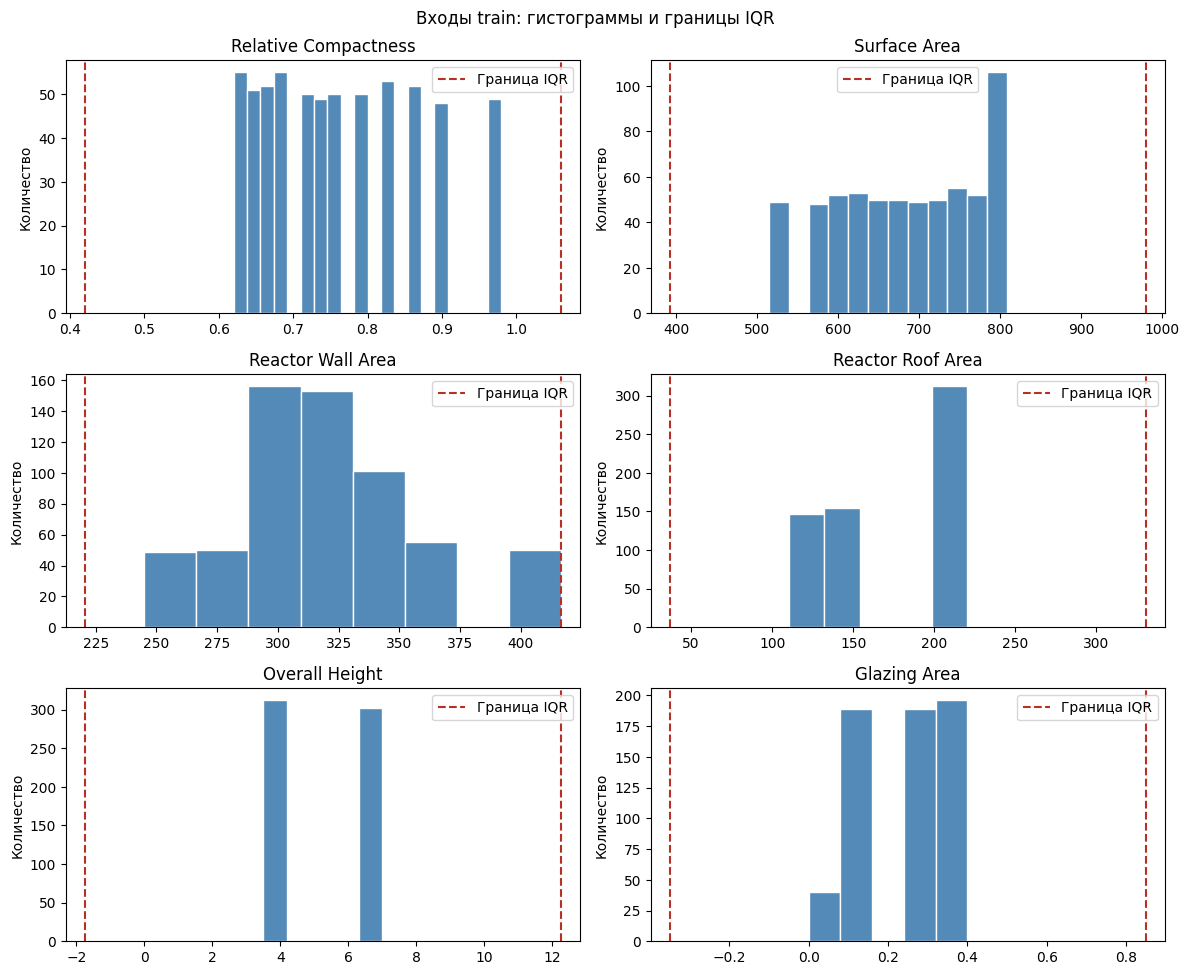

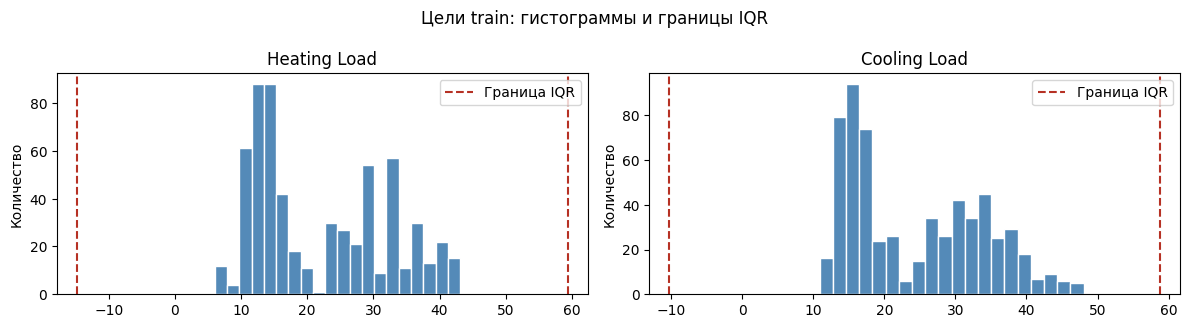

In [3]:
def plot_distributions(frame,bounds,title):
    cols=list(frame)
    fig,axes=plt.subplots((len(cols)+1)//2,2,figsize=(12,3.3*((len(cols)+1)//2)))
    for ax,col in zip(np.ravel(axes),cols):
        s=frame[col]
        low,high=bounds.loc[col,["Нижняя граница","Верхняя граница"]]
        ax.hist(s,bins=min(20,max(5,s.nunique())),color="#548ab8",edgecolor="white")
        ax.axvline(low,color="#b63124",linestyle="--",label="Граница IQR")
        ax.axvline(high,color="#b63124",linestyle="--")
        width=max(s.max(),high)-min(s.min(),low)
        ax.set_xlim(min(s.min(),low)-.04*width,max(s.max(),high)+.04*width)
        ax.set_title(col);ax.set_ylabel("Количество");ax.legend()
    for ax in np.ravel(axes)[len(cols):]: ax.axis("off")
    fig.suptitle(title);fig.tight_layout();plt.show()

plot_distributions(X_train[features],feature_bounds,"Входы train: гистограммы и границы IQR")
plot_distributions(y_train[targets],target_bounds,"Цели train: гистограммы и границы IQR")

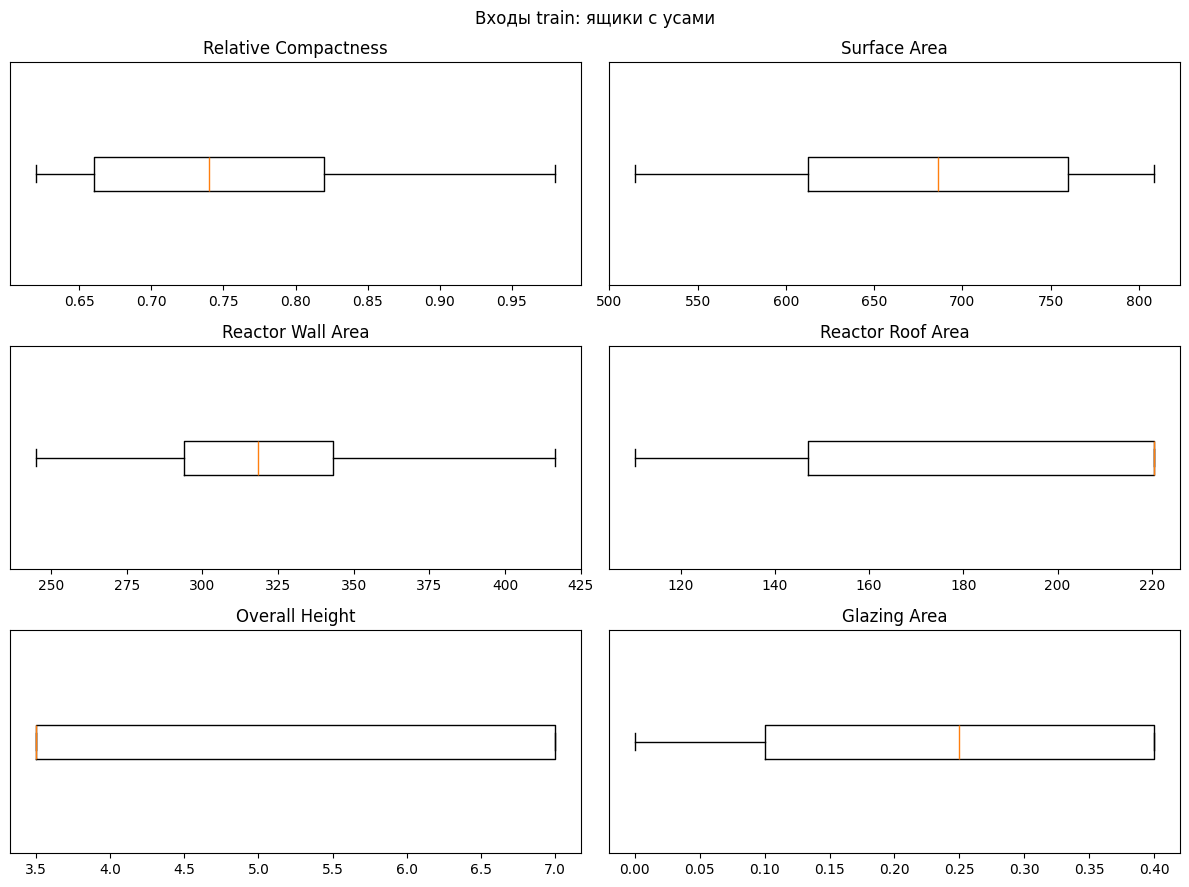

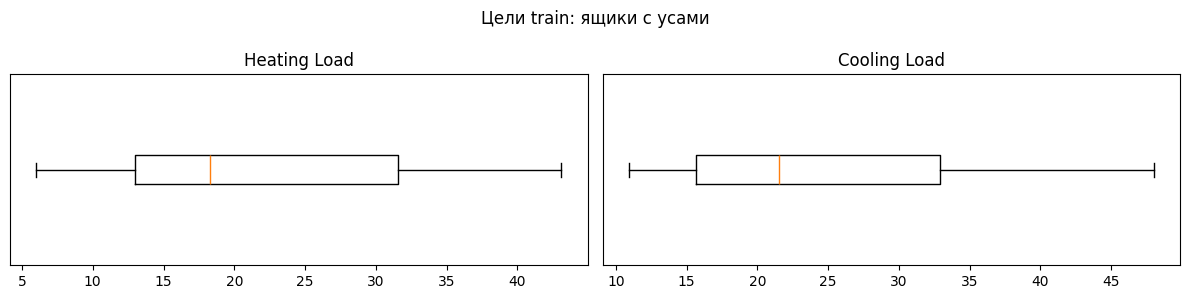

In [4]:
def plot_boxes(frame,title):
    cols=list(frame)
    fig,axes=plt.subplots((len(cols)+1)//2,2,figsize=(12,3*((len(cols)+1)//2)))
    for ax,col in zip(np.ravel(axes),cols):
        ax.boxplot(frame[col].to_numpy(),vert=False,showfliers=True)
        ax.set_title(col);ax.set_yticks([])
    for ax in np.ravel(axes)[len(cols):]: ax.axis("off")
    fig.suptitle(title);fig.tight_layout();plt.show()
plot_boxes(X_train[features],"Входы train: ящики с усами")
plot_boxes(y_train[targets],"Цели train: ящики с усами")

**Вывод:** IQR не обнаружил одномерных выбросов ни в обучающих числовых входах, ни в тестовых по обучающим границам, ни в обучающих целях. Это не исключает редких сочетаний обычных по отдельности значений.

## 3. Аномальные объекты

`StandardScaler` приводит шесть числовых входов к общему масштабу и настраивается на train. `IsolationForest` ищет легко изолируемые строки, `LocalOutlierFactor` (LOF) — строки с меньшей локальной плотностью, чем у соседей. `contamination=0.03` — выбранный порог для диагностического списка, а не известная доля ошибок. LOF использует 20 соседей. Для обучающих строк берём fit_predict; для теста отдельно обучаем LOF в режиме novelty, так как обычный LOF не оценивает новые строки. Пересечение двух списков помогает выбрать строки для ручной проверки. Цели в алгоритмы не передаются.

In [5]:
scaler=StandardScaler().fit(X_train[features])
z_train=scaler.transform(X_train[features])
z_test=scaler.transform(X_test[features])
forest=IsolationForest(n_estimators=300,contamination=.03,random_state=SEED,n_jobs=1).fit(z_train)
lof_train=LocalOutlierFactor(n_neighbors=20,contamination=.03,n_jobs=1)
train_lof_labels=lof_train.fit_predict(z_train)
lof_new=LocalOutlierFactor(n_neighbors=20,contamination=.03,novelty=True,n_jobs=1).fit(z_train)
train_flags=pd.DataFrame({"Isolation Forest":forest.predict(z_train)==-1,
                          "LOF":train_lof_labels==-1},index=X_train.index)
train_flags["Оба метода"]=train_flags.all(axis=1)
test_flags=pd.DataFrame({"Isolation Forest":forest.predict(z_test)==-1,
                         "LOF":lof_new.predict(z_test)==-1},index=X_test.index)
test_flags["Оба метода"]=test_flags.all(axis=1)
print("Обучение:");display(train_flags.sum().to_frame("Количество"))
print("Тест, модели обучены на train:");display(test_flags.sum().to_frame("Количество"))

Обучение:


,Количество
Isolation Forest,19
LOF,16
Оба метода,4


Тест, модели обучены на train:


,Количество
Isolation Forest,5
LOF,0
Оба метода,0


Для отображения объектов в двух измерениях используем PCA, обученный на train. Проекция может скрыть расстояния в исходном шестимерном пространстве: график служит визуализацией, а не подтверждением ошибки.

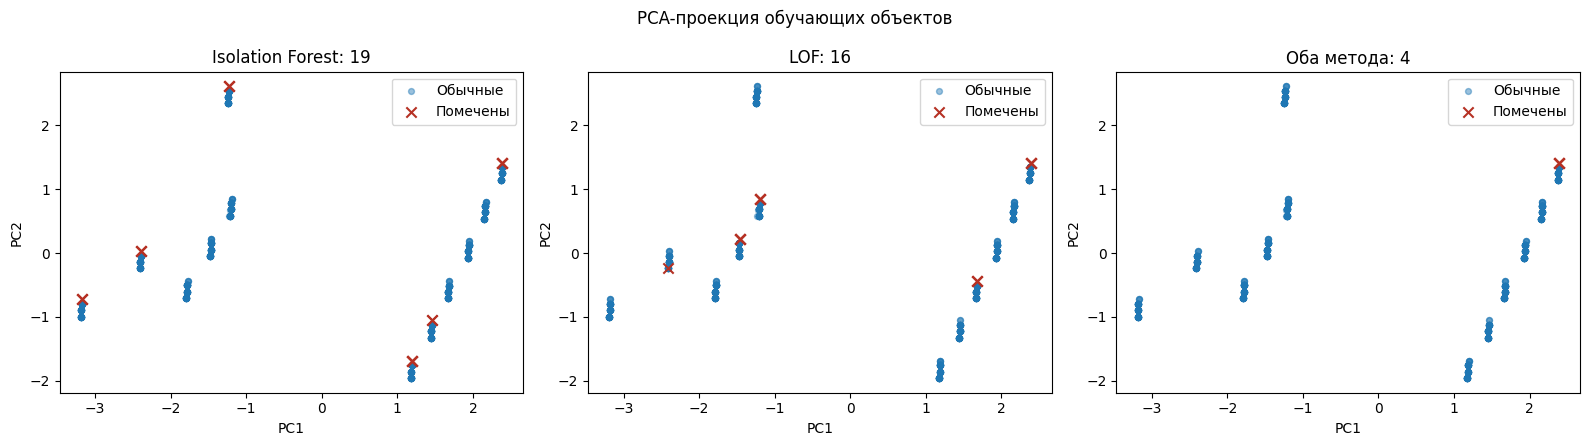

Объяснённая доля дисперсии: 0.824


In [6]:
pca=PCA(n_components=2,random_state=SEED).fit(z_train)
points=pca.transform(z_train)
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for ax,col in zip(axes,train_flags.columns):
    mask=train_flags[col].to_numpy()
    ax.scatter(points[~mask,0],points[~mask,1],s=18,alpha=.45,label="Обычные")
    ax.scatter(points[mask,0],points[mask,1],s=55,marker="x",color="#b63124",label="Помечены")
    ax.set_title(f"{col}: {mask.sum()}");ax.set_xlabel("PC1");ax.set_ylabel("PC2");ax.legend()
fig.suptitle("PCA-проекция обучающих объектов");fig.tight_layout();plt.show()
print("Объяснённая доля дисперсии:",round(float(pca.explained_variance_ratio_.sum()),3))

## 4. Предметная проверка и решение

Проверим строки, которые оба метода считают необычными, в исходном масштабе. Цели смотрим **после** детекции, лишь для интерпретации. Нулевая площадь остекления допустима в датасете. Необычность означает редкость конфигурации, а не доказанную ошибку.

In [7]:
joint_ids=train_flags.index[train_flags["Оба метода"]]
review=pd.concat([X_train.loc[joint_ids,features],
                  X_train.loc[joint_ids,[c for c in X_train if c.startswith("Glazing Area Distribution_")]],
                  y_train.loc[joint_ids,targets]],axis=1)
display(review.round(4))
print("Индексы для проверки:",joint_ids.tolist())
print("Доля без остекления среди кандидатов:",
      round(float((X_train.loc[joint_ids,"Glazing Area"]==0).mean()),3) if len(joint_ids) else 0)
display(X_train[features].agg(["min","max"]).T)

,Relative Compactness,Surface Area,Reactor Wall Area,Reactor Roof Area,Overall Height,Glazing Area,Glazing Area Distribution_0,Glazing Area Distribution_1,Glazing Area Distribution_2,Glazing Area Distribution_3,Glazing Area Distribution_4,Glazing Area Distribution_5,Heating Load,Cooling Load
source_row,,,,,,,,,,,,,,
44,0.62,808.5,367.5,220.5,3.5,0.0,1,0,0,0,0,0,8.60,12.07
46,0.62,808.5,367.5,220.5,3.5,0.0,1,0,0,0,0,0,8.45,12.08
45,0.62,808.5,367.5,220.5,3.5,0.0,1,0,0,0,0,0,8.49,12.22
47,0.62,808.5,367.5,220.5,3.5,0.0,1,0,0,0,0,0,8.50,12.04


Индексы для проверки: [44, 46, 45, 47]
Доля без остекления среди кандидатов: 1.0


,min,max
Relative Compactness,0.62,0.98
Surface Area,514.50,808.50
Reactor Wall Area,245.00,416.50
Reactor Roof Area,110.25,220.50
Overall Height,3.50,7.00
Glazing Area,0.00,0.40


**Решение об удалении.** Правило IQR не нашло выбросов. Совпадение двух алгоритмов отмечает редкие сочетания допустимых геометрических параметров и нулевого остекления. Значения лежат в наблюдаемых диапазонах, нагрузки положительны. Нет подтверждённых ошибок ввода. Поэтому **все строки сохраняются**: удаление допустимых редких объектов уменьшило бы охват будущей модели. Флаги сохраняем отдельно для аудита. Список удаления оставлен пустым сознательно; если будет найдена подтверждённая ошибка, в него можно добавить `source_row`.

In [8]:
confirmed_errors=pd.Index([],name="source_row",dtype=int)
X_train_final=X_train.drop(index=confirmed_errors)
y_train_final=y_train.drop(index=confirmed_errors)
X_test_final=X_test.copy()
y_test_final=y_test.copy()
assert X_train_final.equals(X_train) and y_train_final.equals(y_train)
assert X_test_final.equals(X_test) and y_test_final.equals(y_test)
assert set(X_train_final.index).isdisjoint(X_test_final.index)
OUT=Path("processed");OUT.mkdir(exist_ok=True)
for name,frame in {"X_train":X_train_final,"X_test":X_test_final,
                   "y_train":y_train_final,"y_test":y_test_final}.items():
    frame.to_csv(OUT/f"{name}.csv",sep=";",index_label="source_row")
train_flags.to_csv(OUT/"train_anomaly_flags.csv",sep=";",index_label="source_row")
test_flags.to_csv(OUT/"test_anomaly_flags.csv",sep=";",index_label="source_row")
feature_report.to_csv(OUT/"iqr_feature_bounds.csv",sep=";",index_label="feature")
target_bounds.assign(**{"Выбросов train":target_outliers.sum()}).to_csv(
    OUT/"iqr_target_bounds.csv",sep=";",index_label="target")
print("Итог:",X_train_final.shape,X_test_final.shape,"удалено",len(confirmed_errors))
print("Файлы сохранены в",OUT.resolve())

Итог: (614, 16) (154, 16) удалено 0
Файлы сохранены в /Users/arsenijlogunov/Documents/ChatGPT/Практикум по програмированию/LR3_marvel/processed


## 5. Итог

1. Построены гистограммы с границами IQR и ящики с усами для числовых входов и целей. Одномерных выбросов нет.
2. Isolation Forest и LOF нашли необычные комбинации входов; объекты показаны на PCA-проекции.
3. Проверка редких объектов не обнаружила ошибок, поэтому удалено **0** строк. Решение обосновано предметным смыслом.
4. Train/test и цели не менялись. Тестовые цели не использовались при поиске аномалий.

**Воспроизводимость:** Python 3.12.5, версии библиотек в `requirements.txt`, фиксированный seed 42. Выполнять сверху вниз из папки ЛР 3. [Условие ЛР 3](https://wiki.pmifi.ru/ru/disciplines/programming-workshop-bachelors-5sem/labs/outliers-anomalies).